## AAPL Next-Day Stock Price Prediction

In [ ]:
# Edit all the Mardown cells below with the appropriate information 
# Run all cells, containing your code 
# Save this Jupyter with the outputs of your executed cells
#
# PS: Save again the notebook with this outcome.
# PSPS: Don't forget to include the dataset in your submission

**Team 7:**
* Wenceslao Granados Gomez
* Basma Hameid

**Course:** DAAN 570 - Deep Learning (Fall 2026)

### Problem Statement
* This project predicts the next trading day's Apple (AAPL) closing price from historical market observations. We compare three deep-learning architectures: a one-dimensional Convolutional Neural Network (CNN), Long Short-Term Memory (LSTM), and Gated Recurrent Unit (GRU). Each architecture uses either closing-price information alone or closing-price and trading-volume information, so there are six configurations, all using the same 60-trading-day input window. We compare their forecasts with simple baseline methods to determine whether the added model complexity improves accuracy.

* The study asks:
    1. How do CNN, LSTM, and GRU compare on next-day closing-price prediction?
    2. Does adding trading volume improve test performance?
    3. Do the neural networks outperform simple forecasting baselines?

* The six configurations and the previous-day baseline follow the project proposal. We also added random-walk-with-drift and 5-day moving-average baselines. Validation data is used to select models, and the test data is kept for independent evaluation. The best raw-price model is then improved in the Issues / Improvements section through hyperparameter tuning and a log-return experiment.

* **Keywords:** AAPL, stock-price forecasting, next-day close, time series, CNN, LSTM, GRU, trading volume, chronological testing.

### Data Collection
* **Source (URL):** Yash (Kaggle username yash16jr), "S&P500 All assets - Daily Updated dataset," https://www.kaggle.com/datasets/yash16jr/s-and-p500-daily-update-dataset/data (accessed November 4, 2026).
* **Short Description:** The team extracted Apple's closing price (`Close`) and daily trading volume (`Volume`) from the original `SnP_daily_update.csv` file and saved them as `data/AAPL_only.csv`, which is included with this submission. The script `src/extract_aapl.py` in the GitHub repository recreates this file from the original Kaggle download, and the recreated values match. The dataset contains 4,210 daily records from January 4, 2010, through September 29, 2026. The data is used to predict Apple's next trading day's closing price in dollars.

* **Keywords:** Apple, AAPL, historical closing price, trading volume, daily observations.

### Required packages

The project uses the versions below. `requirements.txt` lists all of them.

| Package | Version |
|---|---|
| Python | 3.12.16 |
| TensorFlow | 2.16.2 |
| Keras | 3.15.1 |
| NumPy | 1.26.4 |
| pandas | 2.2.3 |
| scikit-learn | 1.6.1 |
| KerasTuner | 1.4.8 |

**Install (CPU, or Apple computers):**

```bash
conda create -n stock_eval312 python=3.12.16 -y
conda activate stock_eval312
python -m pip install -r requirements.txt
```

**Install (Linux or WSL with an NVIDIA GPU):** use `requirements-linux-gpu.txt` in the last step instead.

**If you only have this notebook:** install the same versions directly in the last step:

```bash
python -m pip install tensorflow==2.16.2 keras==3.15.1 numpy==1.26.4 pandas==2.2.3 scikit-learn==1.6.1 keras-tuner==1.4.8 matplotlib==3.10.9 joblib==1.6.0 "setuptools<81" jupyter ipykernel
```

**Run:** keep this notebook and `AAPL_only.csv` together (the data file is found automatically in `data/`, `../data/`, or next to the notebook), then choose Run All. No other project files are needed.

**Expected run time:** about 25 minutes on a laptop CPU (Intel Core Ultra 9 185H), which produced the saved outputs, and about 21 minutes on an RTX 4090 Laptop GPU. Most of this is the hyperparameter search, and slower computers will take longer.

`RETRAIN = True` (below) trains everything from scratch. After one complete run, `RETRAIN = False` reloads the saved models instead of training them again.

In [ ]:
import json
import os
import shutil
import time
from datetime import datetime
from pathlib import Path
from types import SimpleNamespace

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # hide TensorFlow info messages

import joblib
import keras
import keras_tuner
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from keras import layers
from sklearn.preprocessing import StandardScaler

print("TensorFlow  ", tf.__version__)
print("Keras       ", keras.__version__)
print("KerasTuner  ", keras_tuner.__version__)
print("NumPy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("GPUs visible:", tf.config.list_physical_devices("GPU") or "none (training on CPU)")

2026-11-09 22:37:19.265935: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-09 22:37:19.352809: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-09 22:37:19.353457: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


TensorFlow   2.16.2
Keras        3.15.1
KerasTuner   1.4.8
NumPy        1.26.4
pandas       2.2.3
scikit-learn 1.6.1
GPUs visible: none (training on CPU)


2026-11-09 22:37:22.846928: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:282] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


In [ ]:
# All project settings live in this cell.
RETRAIN = True          # True: train from scratch. False: reload models saved by an earlier run.

SEED = 42
LOOKBACK = 60           # trading days the network sees to make one prediction
TRAIN_RATIO = 0.70      # oldest 70% of rows
VAL_RATIO = 0.15        # next 15%; the most recent 15% is the test set
MA_WINDOW = 5           # window of the moving-average baseline

EPOCHS = 100            # maximum; early stopping usually ends training sooner
PATIENCE = 10           # epochs without validation improvement before stopping
TUNER_TRIALS = 20       # hyperparameter combinations tried in the improvements section

# Settings shared by all six configurations.
BASE_HPARAMS = {"units": 64, "kernel_size": 5, "dropout": 0.2, "learning_rate": 1e-3, "batch_size": 32}

MODEL_NAMES = ("cnn", "lstm", "gru")
FEATURE_SETS = {"close": ["Close"], "close_volume": ["Close", "Volume"]}
LOG_FEATURE_SETS = {"close": ["log_return"], "close_volume": ["log_return", "log_volume", "volume_change"]}
TARGET_COLUMNS = {"price": "target_price", "log_return": "target_log_return"}


def find_data_file(name="AAPL_only.csv"):
    """Find the dataset whether the notebook runs from the project root, notebooks/, or a flat folder."""
    for folder in (Path("data"), Path("../data"), Path(".")):
        if (folder / name).exists():
            return folder / name
    raise FileNotFoundError(f"{name} not found. Keep it in data/, ../data/, or next to this notebook.")


DATA_PATH = find_data_file()
PROJECT_DIR = DATA_PATH.resolve().parent.parent if DATA_PATH.resolve().parent.name == "data" else DATA_PATH.resolve().parent
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"   # saved models, scalers, metadata
LOG_DIR = ARTIFACTS_DIR / "logs"            # TensorBoard logs
TUNING_DIR = ARTIFACTS_DIR / "tuning"       # KerasTuner trials
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {"blue": "#2a78d6", "orange": "#eb6834", "green": "#1baf7a", "gray": "#898781"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def dollar_axis(ax):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"${value:,.0f}"))


print("Data file:", DATA_PATH)
print("Saved models and logs:", os.path.relpath(ARTIFACTS_DIR))

Data file: ../data/AAPL_only.csv
Saved models and logs: ../artifacts


### Data Preprocessing

The main steps are:

1. Load the AAPL closing price (`Close`) and trading volume (`Volume`) in chronological order, and check for missing values, duplicate dates, and invalid observations.
2. Select Close-only or Close+Volume input features, depending on the model configuration.
3. Define the prediction target as the next trading day's closing price in dollars.
4. Create input sequences using the previous 60 trading days.
5. Divide the dataset chronologically into 70% training, 15% validation, and 15% testing, without randomly shuffling the data.
6. Fit the feature and target scalers using only the training data, then apply the same transformations to the validation and test data.
7. Build `tf.data.Dataset` pipelines to feed batches to the models efficiently.

Model predictions are converted back to dollars with the target scaler before evaluation. The same preprocessing is used across all six configurations to ensure a consistent comparison.

#### Step 1: Load and check the data

In [ ]:
def load_stock_data(path=DATA_PATH, ticker="AAPL"):
    """Read the CSV (two header rows: field, then ticker) into a date-sorted DataFrame."""
    df = pd.read_csv(path, header=[0, 1], index_col=0, parse_dates=True)
    df = df.xs(ticker, axis=1, level=1).sort_index().copy()
    df.index.name = "Date"
    df.columns.name = None
    df["Volume"] = df["Volume"].astype(float)
    return df


def validate_stock_data(df):
    """Stop the notebook if the data breaks a basic assumption."""
    missing = [column for column in ("Close", "Volume") if column not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")
    if df[["Close", "Volume"]].isna().any().any():
        raise ValueError("Found missing values.")
    if (df["Close"] <= 0).any() or (df["Volume"] < 0).any():
        raise ValueError("Found invalid prices or volumes.")
    if df.index.has_duplicates or not df.index.is_monotonic_increasing:
        raise ValueError("Dates must be unique and sorted.")


apple_df = load_stock_data()
validate_stock_data(apple_df)

assert len(apple_df) == 4210, "The first trading date must not be lost when reading the two header rows."
assert str(apple_df.index[0].date()) == "2010-01-04" and str(apple_df.index[-1].date()) == "2026-09-29"

print(pd.Series({
    "rows": len(apple_df),
    "first date": apple_df.index[0].date(),
    "last date": apple_df.index[-1].date(),
    "missing values": int(apple_df.isna().sum().sum()),
    "duplicate dates": int(apple_df.index.duplicated().sum()),
    "zero-volume days": int((apple_df["Volume"] == 0).sum()),
}).to_string())
apple_df.describe().round(2)

rows                      4210
first date          2010-01-04
last date           2026-09-29
missing values               0
duplicate dates              0
zero-volume days             0


,Close,Volume
count,4210.00,4.210000e+03
mean,86.66,2.115031e+08
std,85.33,2.135904e+08
min,5.74,1.791060e+07
25%,18.92,7.328460e+07
50%,40.82,1.247940e+08
75%,150.86,2.788205e+08
max,341.07,1.880998e+09


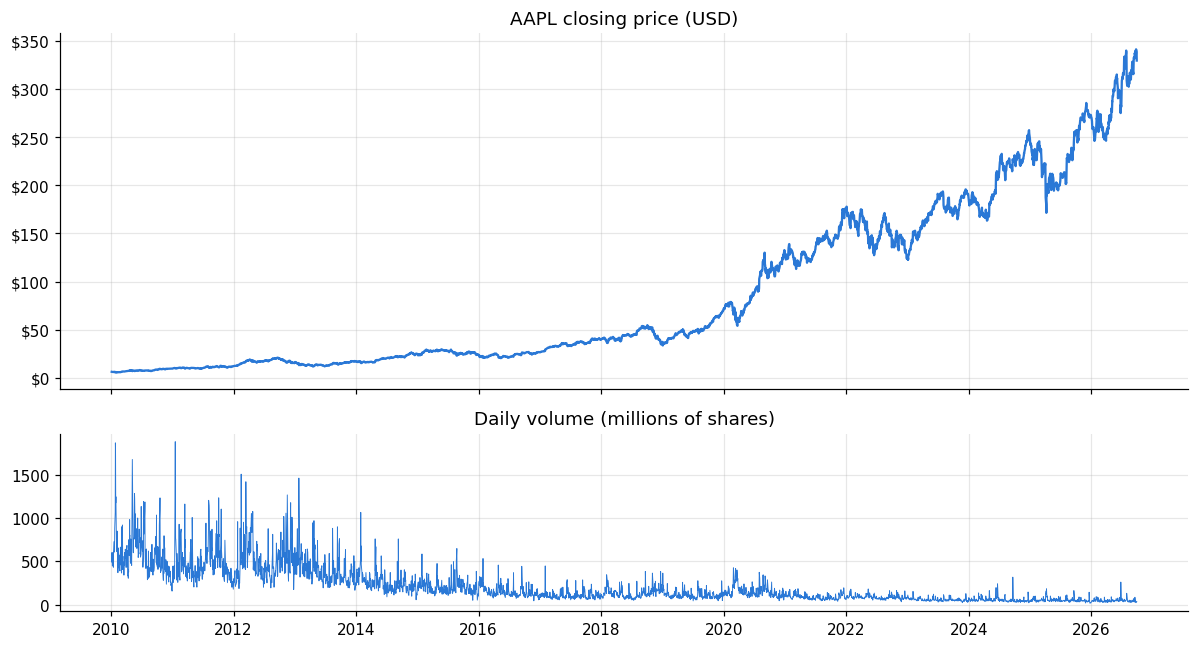

In [ ]:
fig, (ax_price, ax_volume) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax_price.plot(apple_df.index, apple_df["Close"], color=COLORS["blue"])
ax_price.set_title("AAPL closing price (USD)")
dollar_axis(ax_price)
ax_volume.plot(apple_df.index, apple_df["Volume"] / 1e6, color=COLORS["blue"], linewidth=0.6)
ax_volume.set_title("Daily volume (millions of shares)")
fig.tight_layout()
plt.show()

The data passes every check. The closing price rises strongly over the period, especially after 2018, while volume generally falls. Because later prices are much higher than early ones, the chronological split below matters.

#### Steps 2 and 3: Features and target

For each day *t*, the target is the closing price of day *t+1*. `shift(-1)` moves each value one row up, so row *t* receives tomorrow's close. The last row has no tomorrow, so it is removed here and is the day predicted in the deployment demonstration.

The log-return columns are used only as a baseline input (the drift baseline) and in the improvements section. They are not inputs to the six raw-price configurations.

In [ ]:
ENGINEERED_FEATURES = ["log_return", "log_volume", "volume_change"]


def add_features_and_target(df):
    out = df.copy()
    out["log_return"] = np.log(out["Close"] / out["Close"].shift(1))
    out["log_volume"] = np.log1p(out["Volume"])
    out["volume_change"] = out["log_volume"].diff()
    out["next_close"] = out["Close"].shift(-1)
    out["target_date"] = out.index.to_series().shift(-1)
    out["target_price"] = out["next_close"]
    out["target_log_return"] = np.log(out["next_close"] / out["Close"])
    return out


frame = add_features_and_target(apple_df).dropna()   # drops the first and last rows

assert len(frame) == len(apple_df) - 2
assert np.allclose(frame["target_price"].iloc[:-1], frame["Close"].iloc[1:]), "target must be tomorrow's close"
assert (frame["target_date"] > frame.index).all(), "target dates must come after input dates"

frame[["Close", "Volume", "next_close", "target_date"]].head()

,Close,Volume,next_close,target_date
Date,,,,
2010-01-05,6.412026,601904800.0,6.310036,2010-01-06
2010-01-06,6.310036,552160000.0,6.298370,2010-01-07
2010-01-07,6.298370,477131200.0,6.340245,2010-01-08
2010-01-08,6.340245,447610800.0,6.284315,2010-01-11
2010-01-11,6.284315,462229600.0,6.212829,2010-01-12


#### Steps 4 to 7: Split, scale, create windows, and build `tf.data` pipelines

A window for day *t* may reach back into the previous split. Those are past values known on day *t*, so this is safe. The last training and validation samples are excluded because their targets would fall in the following split. The scalers learn only from training rows, so no future information reaches the model.

Each `tf.data.Dataset` batches the windows without shuffling, as the proposal specifies, then caches and prefetches batches so training doesn't wait on data.

In [ ]:
def chronological_split_indices(n_rows, train_ratio=TRAIN_RATIO, val_ratio=VAL_RATIO):
    """Return (train_end, val_end): train = [0, train_end), val = [train_end, val_end), test = [val_end, n_rows)."""
    return int(n_rows * train_ratio), int(n_rows * (train_ratio + val_ratio))


def make_windows(features_scaled, lookback, start, end):
    """Build windows for days t in [start, end). Each ends on day t and has shape (lookback, n_features)."""
    t_idx = np.arange(max(start, lookback - 1), end)
    X = np.stack([features_scaled[t - lookback + 1 : t + 1] for t in t_idx]).astype("float32")
    return X, t_idx


def prepare_data(frame, feature_columns, target_mode="price", lookback=LOOKBACK, feature_scaler=None, target_scaler=None):
    """Split, scale, and window the data. Pass saved scalers to reuse the training transformation exactly."""
    train_end, val_end = chronological_split_indices(len(frame))
    target_values = frame[[TARGET_COLUMNS[target_mode]]].to_numpy()

    if feature_scaler is None or target_scaler is None:
        # train_end - 1: the last training row's target belongs to the validation period.
        feature_scaler = StandardScaler().fit(frame[feature_columns].to_numpy()[: train_end - 1])
        target_scaler = StandardScaler().fit(target_values[: train_end - 1])

    features_scaled = feature_scaler.transform(frame[feature_columns].to_numpy())
    target_scaled = target_scaler.transform(target_values).ravel()

    boundaries = {"train": (0, train_end), "val": (train_end, val_end), "test": (val_end, len(frame))}
    splits = {}
    for name, (start, end) in boundaries.items():
        X, t_idx = make_windows(features_scaled, lookback, start, end)
        if name != "test":   # this sample's target falls in the next split
            X, t_idx = X[:-1], t_idx[:-1]
        splits[name] = SimpleNamespace(
            X=X,
            y=target_scaled[t_idx].astype("float32"),
            row_idx=t_idx,
            dates=frame.index[t_idx],
            target_dates=pd.DatetimeIndex(frame["target_date"].iloc[t_idx]),
            close_t=frame["Close"].to_numpy()[t_idx],
            next_close=frame["next_close"].to_numpy()[t_idx],
        )
    return SimpleNamespace(frame=frame, feature_columns=list(feature_columns), target_mode=target_mode, lookback=lookback,
                           feature_scaler=feature_scaler, target_scaler=target_scaler, splits=splits, boundaries=boundaries)


def make_dataset(split, batch_size):
    """tf.data pipeline for one split. It keeps chronological order: there is no shuffle step."""
    return (tf.data.Dataset.from_tensor_slices((split.X, split.y))
            .batch(batch_size)
            .cache()
            .prefetch(tf.data.AUTOTUNE))


DATA = {name: prepare_data(frame, columns) for name, columns in FEATURE_SETS.items()}

data = DATA["close_volume"]
pd.DataFrame([{
    "split": name,
    "samples": len(s.y),
    "first target date": s.target_dates.min().date(),
    "last target date": s.target_dates.max().date(),
    "X shape": s.X.shape,
    "lowest actual close": round(s.next_close.min(), 2),
    "highest actual close": round(s.next_close.max(), 2),
} for name, s in data.splits.items()]).set_index("split")

,samples,first target date,last target date,X shape,lowest actual close,highest actual close
split,,,,,,
train,2885,2010-04-01,2021-09-15,"(2885, 60, 2)",7.05,152.83
val,630,2021-09-17,2024-03-20,"(630, 60, 2)",122.83,195.72
test,632,2024-03-22,2026-09-29,"(632, 60, 2)",163.22,341.07


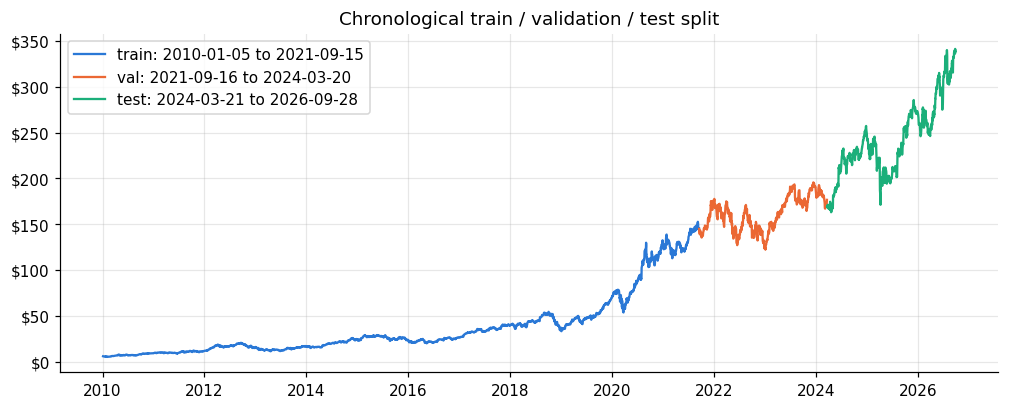

Example pipeline output: (TensorSpec(shape=(None, 60, 2), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))


In [ ]:
# Checks: same samples as designed, and no information crossing a split boundary.
for data in DATA.values():
    assert [len(s.y) for s in data.splits.values()] == [2885, 630, 632]
    train_end, val_end = data.boundaries["train"][1], data.boundaries["val"][1]
    assert data.splits["train"].target_dates[-1] < data.frame.index[train_end], "train target leaks into validation"
    assert data.splits["val"].target_dates[-1] < data.frame.index[val_end], "validation target leaks into test"
    # The scaler's mean must equal the mean of training rows alone.
    train_rows = data.frame[data.feature_columns].to_numpy()[: train_end - 1]
    assert np.allclose(data.feature_scaler.mean_, train_rows.mean(axis=0)), "scaler must use training rows only"

# Both feature sets predict exactly the same days, so the comparison is fair.
assert DATA["close"].splits["test"].target_dates.equals(DATA["close_volume"].splits["test"].target_dates)

fig, ax = plt.subplots(figsize=(11, 4))
for (name, (start, end)), color in zip(DATA["close"].boundaries.items(), (COLORS["blue"], COLORS["orange"], COLORS["green"])):
    part = frame.iloc[start:end]
    ax.plot(part.index, part["Close"], color=color, label=f"{name}: {part.index.min().date()} to {part.index.max().date()}")
ax.set_title("Chronological train / validation / test split")
dollar_axis(ax)
ax.legend(loc="upper left")
plt.show()

print("Example pipeline output:", make_dataset(DATA["close_volume"].splits["train"], BASE_HPARAMS["batch_size"]).element_spec)

All checks pass, and each configuration has 2,885 training, 630 validation, and 632 test samples. The chart shows the main challenge of predicting raw prices: **every test price is above the highest price seen in training**, so the models must predict levels they have never seen.

### Methodology

1. **Deep Learning process**

The project uses historical Apple stock data to predict the next trading day's closing price. The process includes preparing the data in chronological order, creating input sequences, training the neural networks, monitoring validation loss, and evaluating predictions on a separate test dataset. Each neural network is evaluated with two input combinations, Close-only and Close+Volume. This results in six configurations, all using the same data partitions and 60-day input window.

Common training settings: all six configurations use the Adam optimizer with a learning rate of 0.001, Huber loss, a batch size of 32, a dropout rate of 0.2, and up to 100 training epochs. Early stopping has a patience of 10 epochs, the learning rate is halved when validation loss stops improving, and the random seed is 42. The actual number of completed epochs varies by model.

2. **Deep Neural Networks used**

* **Model 1: 1D-CNN**
    * A Convolutional Neural Network uses filters to identify patterns in historical stock data. Layers: `Conv1D` (64 filters, kernel size 5), `GlobalMaxPooling1D`, `Dropout`, `Dense(1)`. It is evaluated with both input combinations.

* **Model 2: LSTM**
    * A Long Short-Term Memory network is designed to learn patterns over time and retain information from previous observations. Layers: `LSTM(64)`, `Dropout`, `Dense(1)`. It is evaluated with both input combinations.

* **Model 3: GRU**
    * A Gated Recurrent Unit network is similar to LSTM but has a simpler internal structure. Layers: `GRU(64)`, `Dropout`, `Dense(1)`. It is evaluated with both input combinations.

* **Baseline methods** (no machine learning)
    * Naive persistence uses the current closing price as the next closing price. Random walk with drift multiplies the current close by the average daily growth observed in training. The 5-day moving average uses the mean of the last five closes. These methods show whether the deep-learning models add accuracy.

3. **Tools applied from the course case studies**

* `tf.data.Dataset` loads the data efficiently.
* TensorBoard records and visualizes training for every run.
* Each model is saved as a `.keras` file with its scalers and settings, then reloaded and checked.
* KerasTuner tunes the hyperparameters of the best raw-price model in the Issues / Improvements section.

**Keywords:** supervised learning, time-series forecasting, 1D-CNN, LSTM, GRU, Adam optimization, baseline comparison, hyperparameter tuning.

### Model Fitting and Validation

Six models are trained to predict the next trading day's closing price. Each trained model is saved with its scalers, metadata, and training history. Validation loss selects the model used for the improvements and the historical deployment demonstration, and the test set plays no part in that choice.

1. **1D-CNN:** Close-only and Close+Volume
2. **LSTM:** Close-only and Close+Volume
3. **GRU:** Close-only and Close+Volume

In [ ]:
def build_model(name, input_shape, units=64, kernel_size=5, dropout=0.2, learning_rate=1e-3):
    """Build and compile one of the three architectures."""
    if name == "lstm":
        core = [layers.LSTM(units)]
    elif name == "gru":
        core = [layers.GRU(units)]
    elif name == "cnn":
        core = [layers.Conv1D(units, kernel_size=kernel_size, activation="relu"), layers.GlobalMaxPooling1D()]
    else:
        raise ValueError(f"Unknown model: {name}")
    model = keras.Sequential([layers.Input(shape=input_shape), *core, layers.Dropout(dropout), layers.Dense(1)], name=name)
    # Huber loss limits the influence of a few extreme market days on training.
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss=keras.losses.Huber(delta=1.0),
                  metrics=[keras.metrics.MeanAbsoluteError(name="mae")])
    return model


def training_callbacks(log_dir):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(1, PATIENCE // 2), min_lr=1e-5),
        keras.callbacks.TensorBoard(log_dir=str(log_dir)),
    ]


def save_run(run_dir, model, data, history, metadata):
    """Serialization: the model alone isn't enough, so save its scalers and settings beside it."""
    run_dir.mkdir(parents=True, exist_ok=True)
    model.save(str(run_dir / "model.keras"))
    joblib.dump(data.feature_scaler, run_dir / "feature_scaler.joblib")
    joblib.dump(data.target_scaler, run_dir / "target_scaler.joblib")
    (run_dir / "history.json").write_text(json.dumps(history, indent=2), encoding="utf-8")
    (run_dir / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")


def load_run(run_name):
    """Reload everything needed to use a saved model, without any training."""
    run_dir = ARTIFACTS_DIR / run_name
    return SimpleNamespace(
        model=keras.models.load_model(str(run_dir / "model.keras"), compile=False),
        feature_scaler=joblib.load(run_dir / "feature_scaler.joblib"),
        target_scaler=joblib.load(run_dir / "target_scaler.joblib"),
        history=json.loads((run_dir / "history.json").read_text(encoding="utf-8")),
        metadata=json.loads((run_dir / "metadata.json").read_text(encoding="utf-8")),
    )


def train_run(run_name, model_name, data, hparams=BASE_HPARAMS, retrain=None):
    """Train and save one configuration, or reload it when RETRAIN is False."""
    retrain = RETRAIN if retrain is None else retrain
    if not retrain:
        saved = load_run(run_name)
        return SimpleNamespace(run_name=run_name, model=saved.model, history=saved.history,
                               metadata=saved.metadata, data=data)

    keras.utils.set_random_seed(SEED)
    keras.backend.clear_session()
    log_dir = LOG_DIR / run_name
    shutil.rmtree(log_dir, ignore_errors=True)

    train, val = data.splits["train"], data.splits["val"]
    model = build_model(model_name, train.X.shape[1:], units=hparams["units"], kernel_size=hparams["kernel_size"],
                        dropout=hparams["dropout"], learning_rate=hparams["learning_rate"])
    start = time.time()
    fit = model.fit(make_dataset(train, hparams["batch_size"]),
                    validation_data=make_dataset(val, hparams["batch_size"]),
                    epochs=EPOCHS, callbacks=training_callbacks(log_dir), shuffle=False, verbose=0)
    seconds = time.time() - start

    history = {key: [float(value) for value in values] for key, values in fit.history.items()}
    metadata = {
        "run_name": run_name, "model_name": model_name, "target_mode": data.target_mode,
        "feature_columns": data.feature_columns, "lookback": data.lookback, "hparams": hparams,
        "epochs_run": len(history["loss"]), "best_epoch": int(np.argmin(history["val_loss"])) + 1,
        "best_val_loss": float(min(history["val_loss"])), "n_parameters": int(model.count_params()),
        "train_seconds": round(seconds, 1), "trained_at": datetime.now().isoformat(timespec="seconds"),
        "tensorflow_version": tf.__version__,
    }
    save_run(ARTIFACTS_DIR / run_name, model, data, history, metadata)
    print(f"{run_name:20s} {metadata['epochs_run']:3d} epochs, best epoch {metadata['best_epoch']:3d}, "
          f"val_loss {metadata['best_val_loss']:.4f}, {seconds:.0f}s")
    return SimpleNamespace(run_name=run_name, model=model, history=history, metadata=metadata, data=data)

In [ ]:
RESULTS = {}
for model_name in MODEL_NAMES:
    for feature_set, data in DATA.items():
        run_name = f"{model_name}_{feature_set}"
        RESULTS[run_name] = train_run(run_name, model_name, data)

validation_table = pd.DataFrame([{
    "run": name,
    "best val loss": run.metadata["best_val_loss"],
    "parameters": run.metadata["n_parameters"],
    "epochs run": run.metadata["epochs_run"],
    "best epoch": run.metadata["best_epoch"],
    "train seconds": run.metadata["train_seconds"],
} for name, run in RESULTS.items()]).set_index("run").sort_values("best val loss")

# Model selection uses the validation set only. The test set just reports the result.
selected_run = validation_table["best val loss"].idxmin()
print("Selected model (lowest validation loss):", selected_run)
validation_table.round(4)

cnn_close             36 epochs, best epoch  26, val_loss 0.0545, 9s


cnn_close_volume      19 epochs, best epoch   9, val_loss 0.0521, 5s


lstm_close            31 epochs, best epoch  21, val_loss 0.0083, 36s


lstm_close_volume     24 epochs, best epoch  14, val_loss 0.0188, 28s


gru_close             15 epochs, best epoch   5, val_loss 0.0088, 20s


gru_close_volume      26 epochs, best epoch  16, val_loss 0.0053, 34s
Selected model (lowest validation loss): gru_close_volume


,best val loss,parameters,epochs run,best epoch,train seconds
run,,,,,
gru_close_volume,0.0053,13121,26,16,34.0
lstm_close,0.0083,16961,31,21,35.9
gru_close,0.0088,12929,15,5,19.8
lstm_close_volume,0.0188,17217,24,14,27.7
cnn_close_volume,0.0521,769,19,9,5.0
cnn_close,0.0545,449,36,26,9.0


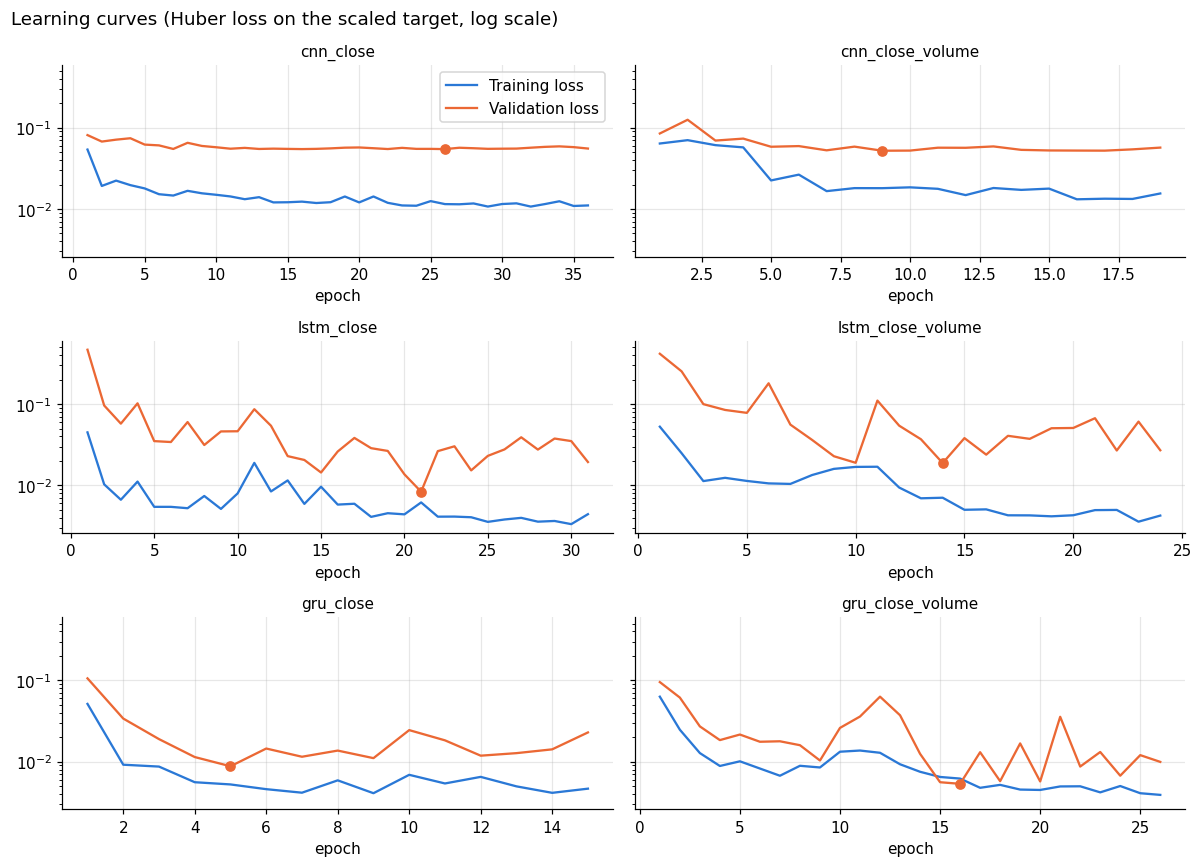

In [ ]:
# Learning curves: one panel per run. The dot marks the best validation epoch.
fig, axes = plt.subplots(len(MODEL_NAMES), len(DATA), figsize=(11, 8), sharex=False, sharey=True)
for ax, (name, run) in zip(axes.ravel(), RESULTS.items()):
    epochs = np.arange(1, len(run.history["loss"]) + 1)
    best = int(np.argmin(run.history["val_loss"]))
    ax.plot(epochs, run.history["loss"], color=COLORS["blue"], label="Training loss")
    ax.plot(epochs, run.history["val_loss"], color=COLORS["orange"], label="Validation loss")
    ax.scatter([epochs[best]], [run.history["val_loss"][best]], color=COLORS["orange"], zorder=3)
    ax.set_yscale("log")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("epoch")
axes[0, 0].legend(loc="upper right")
fig.suptitle("Learning curves (Huber loss on the scaled target, log scale)", x=0.01, ha="left")
fig.tight_layout()
plt.show()

**TensorBoard.** The next cell opens TensorBoard with every run's training curves, including the tuning trials from the improvements section once they have run. The embedded view needs a live session, so it may appear blank in a saved copy of this notebook, which is why the curves above are also plotted directly. To view the logs from a terminal, run `tensorboard --logdir artifacts/logs`.

In [ ]:
%load_ext tensorboard
%tensorboard --logdir "{LOG_DIR}"

**Training results.** The GRU Close+Volume model had the lowest validation loss (0.0053), so it was selected for the improvements and the historical deployment demonstration. LSTM Close-only (0.0083) and GRU Close-only (0.0088) came next, followed by LSTM Close+Volume (0.0188). Both CNN models had much higher validation losses (0.0521 and 0.0545), and they are also much smaller: 449 and 769 parameters, compared with 12,929 to 17,217 for the LSTM and GRU models.

Early stopping ended every run between 15 and 36 epochs, well short of the 100-epoch limit, and each run took about 5 to 36 seconds on the CPU. The GRU Close+Volume model completed 26 epochs, with its best validation result at epoch 16.

The learning curves show validation loss generally staying above training loss. The LSTM and GRU validation curves are noisy from epoch to epoch, including around the selected model's best epoch, so the small differences between the leading models should not be overinterpreted.

Validation loss is used during model training and selection, while test RMSE is used to evaluate prediction accuracy on unseen data. These two measures serve different purposes and should not be directly compared.

### Model Evaluation

The held-out test evaluation covers 632 predictions from March 22, 2024, through September 29, 2026. Four metrics measure prediction accuracy:

* **MAE:** the average prediction error in dollars.
* **RMSE:** like MAE, but gives greater weight to larger errors.
* **MAPE:** the prediction error as a percentage of the price.
* **Directional accuracy:** how often the model correctly predicts whether the price will rise or fall.

Lower MAE, RMSE, and MAPE indicate better accuracy, while higher directional accuracy is better. The naive baseline never predicts a move, so it has no directional accuracy.

In [ ]:
BASELINES = {
    "naive": "Naive baseline",
    "drift": "Random walk + drift",
    "moving_average": f"{MA_WINDOW}-day moving average",
}


def to_price(pred_target, close_t, target_mode):
    """Convert predictions in target units into next-day prices in dollars."""
    return close_t * np.exp(pred_target) if target_mode == "log_return" else pred_target


def predict_split(model, data, split="test"):
    """Predictions and baselines in dollars for one split, indexed by the predicted date."""
    s = data.splits[split]
    pred_scaled = model.predict(s.X, verbose=0).reshape(-1, 1)
    pred_target = data.target_scaler.inverse_transform(pred_scaled).ravel()
    drift = data.frame["log_return"].iloc[: data.boundaries["train"][1]].mean()   # measured on training rows only
    table = pd.DataFrame({
        "close_t": s.close_t,
        "actual": s.next_close,
        "predicted": to_price(pred_target, s.close_t, data.target_mode),
        "naive": s.close_t,
        "drift": s.close_t * np.exp(drift),
        "moving_average": data.frame["Close"].rolling(MA_WINDOW).mean().to_numpy()[s.row_idx],
    }, index=s.target_dates)
    table.index.name = "target_date"
    return table


def regression_metrics(actual, predicted, prev_close):
    actual, predicted, prev_close = (np.asarray(x, dtype=float) for x in (actual, predicted, prev_close))
    errors = predicted - actual
    predicted_move, actual_move = np.sign(predicted - prev_close), np.sign(actual - prev_close)
    direction = np.nan if np.all(predicted_move == 0) else float(np.mean(predicted_move == actual_move) * 100)
    return {
        "MAE": float(np.mean(np.abs(errors))),
        "RMSE": float(np.sqrt(np.mean(errors ** 2))),
        "MAPE_%": float(np.mean(np.abs(errors / actual)) * 100),
        "DirAcc_%": direction,
    }


def comparison_table(runs, split="test"):
    """One table with every run and every baseline, sorted by RMSE."""
    rows, predictions = [], None
    for name, run in runs.items():
        predictions = predict_split(run.model, run.data, split)
        rows.append({"run": name, "kind": "model",
                     **regression_metrics(predictions["actual"], predictions["predicted"], predictions["close_t"])})
    for column, label in BASELINES.items():
        rows.append({"run": label, "kind": "baseline",
                     **regression_metrics(predictions["actual"], predictions[column], predictions["close_t"])})
    return pd.DataFrame(rows).set_index("run").sort_values("RMSE")


test_table = comparison_table(RESULTS)

# Baselines don't depend on training, so they must match the values documented for this dataset.
assert abs(test_table.loc["Naive baseline", "RMSE"] - 4.1577) < 5e-4
assert abs(test_table.loc["Random walk + drift", "RMSE"] - 4.1520) < 5e-4
assert abs(test_table.loc[f"{MA_WINDOW}-day moving average", "RMSE"] - 6.4502) < 5e-4

test_table.round(4)

,kind,MAE,RMSE,MAPE_%,DirAcc_%
run,,,,,
Random walk + drift,baseline,2.8363,4.1520,1.1852,55.2215
Naive baseline,baseline,2.8533,4.1577,1.1918,NaN
5-day moving average,baseline,4.7336,6.4502,1.9777,48.8924
cnn_close,model,12.3148,14.7613,5.2402,49.0506
cnn_close_volume,model,13.7530,16.3988,5.7154,46.8354
gru_close_volume,model,25.1869,32.5438,9.3760,44.1456
gru_close,model,32.1938,40.4717,12.0630,44.3038
lstm_close,model,38.5927,49.3220,14.3756,44.7785
lstm_close_volume,model,54.7756,65.3250,20.8345,45.5696


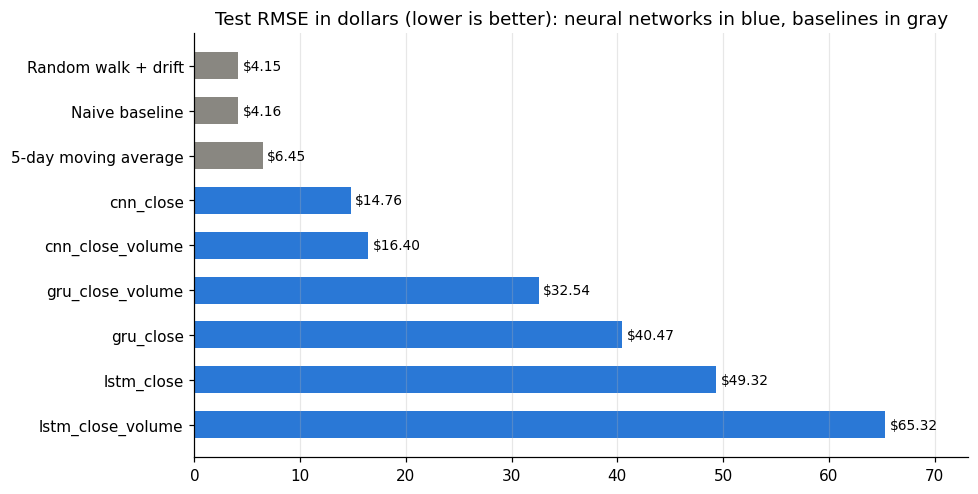

,RMSE close,RMSE close + volume,RMSE change with volume ($)
model,,,
cnn,14.7613,16.3988,1.6375
lstm,49.3220,65.3250,16.0030
gru,40.4717,32.5438,-7.9279


In [ ]:
plot_table = test_table.sort_values("RMSE")
fig, ax = plt.subplots(figsize=(9, 4.6))
bars = ax.barh(plot_table.index, plot_table["RMSE"], height=0.6,
               color=[COLORS["gray"] if kind == "baseline" else COLORS["blue"] for kind in plot_table["kind"]])
ax.bar_label(bars, fmt="$%.2f", padding=3, fontsize=9)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.margins(x=0.12)
ax.set_title("Test RMSE in dollars (lower is better): neural networks in blue, baselines in gray")
fig.tight_layout()
plt.show()

# Effect of trading volume: each architecture compared with itself.
volume_effect = pd.DataFrame([{
    "model": model_name,
    "RMSE close": test_table.loc[f"{model_name}_close", "RMSE"],
    "RMSE close + volume": test_table.loc[f"{model_name}_close_volume", "RMSE"],
    "RMSE change with volume ($)": test_table.loc[f"{model_name}_close_volume", "RMSE"] - test_table.loc[f"{model_name}_close", "RMSE"],
} for model_name in MODEL_NAMES]).set_index("model")
volume_effect.round(4)

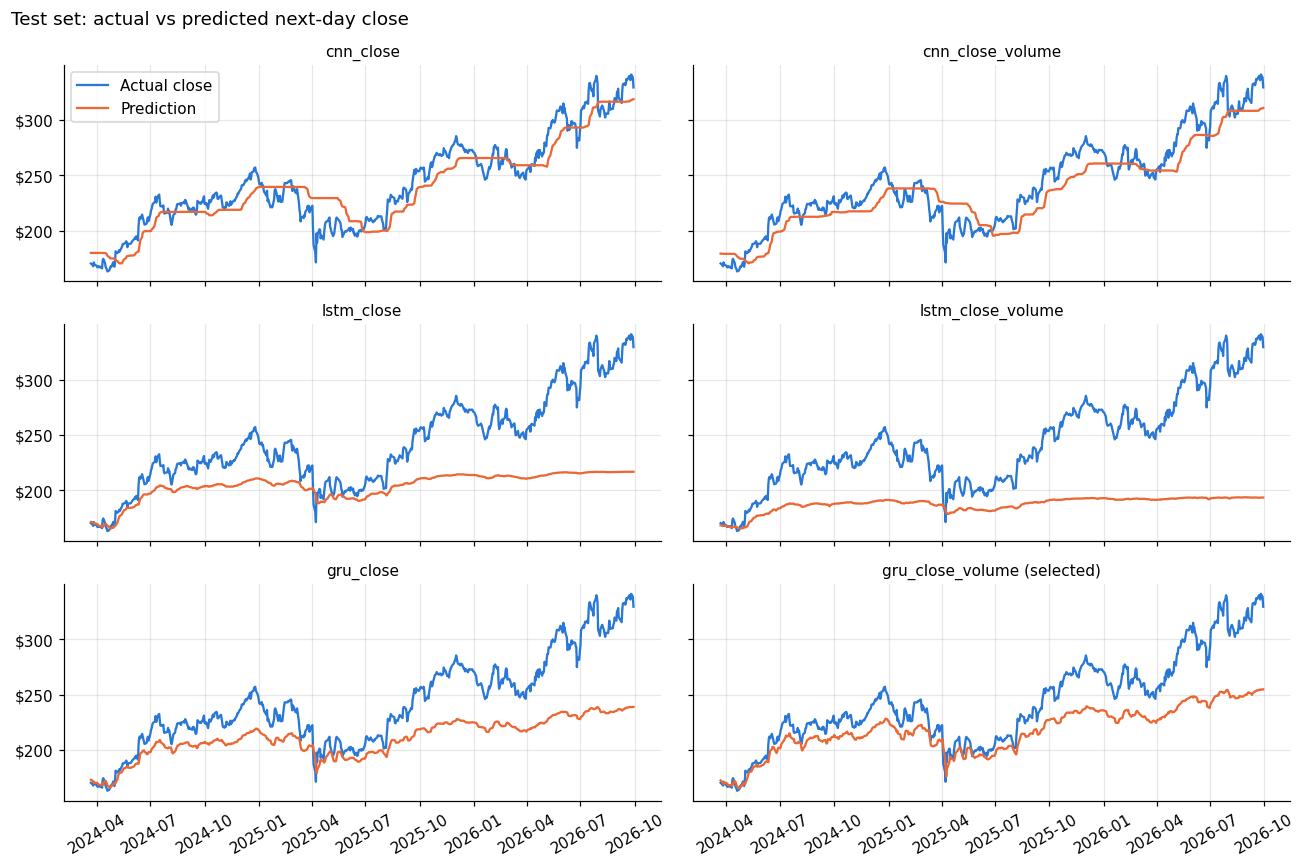

In [ ]:
# Actual vs predicted closing prices on the test set for all six configurations.
fig, axes = plt.subplots(len(MODEL_NAMES), len(DATA), figsize=(12, 8), sharex=True, sharey=True)
for ax, (name, run) in zip(axes.ravel(), RESULTS.items()):
    predictions = predict_split(run.model, run.data)
    ax.plot(predictions.index, predictions["actual"], color=COLORS["blue"], label="Actual close")
    ax.plot(predictions.index, predictions["predicted"], color=COLORS["orange"], label="Prediction")
    ax.set_title(name + (" (selected)" if name == selected_run else ""), fontsize=10)
    dollar_axis(ax)
    ax.tick_params(axis="x", labelrotation=30)
axes[0, 0].legend(loc="upper left")
fig.suptitle("Test set: actual vs predicted next-day close", x=0.01, ha="left")
fig.tight_layout()
plt.show()

In [ ]:
# How the selected model errs: signed error is actual minus predicted, so positive means it predicted too low.
selected = RESULTS[selected_run]
selected_predictions = predict_split(selected.model, selected.data)
signed_error = selected_predictions["actual"] - selected_predictions["predicted"]

train_rows = frame.iloc[: selected.data.boundaries["train"][1]]
print("Selected model:", selected_run)
print(f"Predicted too low on {(signed_error > 0).sum()} of {len(signed_error)} test days ({(signed_error > 0).mean() * 100:.1f}%)")
print(f"Average signed error: ${signed_error.mean():+.2f}")
print(f"Closing prices in training rows: ${train_rows['Close'].min():.2f} to ${train_rows['Close'].max():.2f}")
print(f"Actual closes in the test set:   ${selected_predictions['actual'].min():.2f} to ${selected_predictions['actual'].max():.2f}")
signed_error.groupby(signed_error.index.year).mean().round(2).rename("mean signed error ($)").to_frame()

Selected model: gru_close_volume
Predicted too low on 602 of 632 test days (95.3%)
Average signed error: $+24.88
Closing prices in training rows: $5.74 to $152.83
Actual closes in the test set:   $163.22 to $341.07


,mean signed error ($)
target_date,
2024,11.04
2025,17.76
2026,49.04


#### Saved models and historical deployment demonstration

This section reloads the selected model from disk and first confirms it gives the same predictions as the trained model. It then predicts the day after the last row of the dataset, and replays the last 20 trading days using only data available on each day. This is a historical demonstration, not a current stock-price forecast.

In [ ]:
def predict_next_day(model, data, history_df):
    """Predict the close of the trading day after the last row of history_df, with the training preprocessing."""
    features = add_features_and_target(history_df).dropna(subset=ENGINEERED_FEATURES)
    window = features[data.feature_columns].to_numpy()[-data.lookback:]
    x = data.feature_scaler.transform(window)[np.newaxis, ...].astype("float32")
    pred_target = float(data.target_scaler.inverse_transform(model.predict(x, verbose=0).reshape(-1, 1))[0, 0])
    last_close = float(features["Close"].iloc[-1])
    predicted_close = float(to_price(pred_target, last_close, data.target_mode))
    return {
        "last date": features.index[-1].date(),
        "last close": last_close,
        "next date (estimated)": (features.index[-1] + pd.offsets.BDay(1)).date(),
        "predicted close": predicted_close,
        "predicted change (%)": (predicted_close / last_close - 1) * 100,
    }


def simulate_recent(model, data, days=20):
    """Replay the last trading days, using only the data known on each day."""
    rows = []
    for as_of in apple_df.index[-(days + 1):-1]:
        prediction = predict_next_day(model, data, apple_df.loc[:as_of])
        actual_next = apple_df["Close"].iloc[apple_df.index.get_loc(as_of) + 1]
        rows.append({"as of": as_of.date(), "last close": prediction["last close"],
                     "predicted next": prediction["predicted close"], "actual next": actual_next,
                     "error ($)": prediction["predicted close"] - actual_next})
    return pd.DataFrame(rows).set_index("as of")


# Serialization check: rebuild the data with the saved scalers and compare predictions with the trained model.
reloaded = load_run(selected_run)
reloaded_data = prepare_data(frame, reloaded.metadata["feature_columns"], target_mode=reloaded.metadata["target_mode"],
                             feature_scaler=reloaded.feature_scaler, target_scaler=reloaded.target_scaler)
reloaded_predictions = predict_split(reloaded.model, reloaded_data)
assert np.allclose(reloaded_predictions["predicted"], selected_predictions["predicted"], atol=1e-3)
print("Saved model reloaded: predictions match the trained model.")
print("Files:", sorted(p.name for p in (ARTIFACTS_DIR / selected_run).iterdir()))

print(pd.Series(predict_next_day(reloaded.model, reloaded_data, apple_df)).to_string())
simulation = simulate_recent(reloaded.model, reloaded_data)
print(f"\nMAE over the last {len(simulation)} days: ${simulation['error ($)'].abs().mean():.2f}")
print(f"Predicted too low on {(simulation['error ($)'] < 0).sum()} of {len(simulation)} days")
simulation.round(2)

Saved model reloaded: predictions match the trained model.
Files: ['feature_scaler.joblib', 'history.json', 'metadata.json', 'model.keras', 'target_scaler.joblib']
last date                2026-09-29
last close               329.399994
next date (estimated)    2026-09-30
predicted close          253.654678
predicted change (%)     -22.994935



MAE over the last 20 days: $78.24
Predicted too low on 20 of 20 days


,last close,predicted next,actual next,error ($)
as of,,,,
2026-08-31,316.85,249.94,325.13,-75.19
2026-09-01,325.13,251.04,324.96,-73.92
2026-09-02,324.96,251.43,328.21,-76.78
2026-09-03,328.21,252.10,319.97,-67.87
2026-09-04,319.97,251.22,316.22,-65.00
2026-09-08,316.22,250.38,315.34,-64.96
2026-09-09,315.34,249.88,326.57,-76.69
2026-09-10,326.57,251.15,332.27,-81.12
2026-09-11,332.27,252.39,333.08,-80.69


**Model performance comparison.** The CNN Close-only model achieved the lowest RMSE among the six deep-learning configurations (\$14.76). However, the random walk with drift baseline achieved an RMSE of \$4.15 and the naive baseline \$4.16. Both performed substantially better than all six deep-learning models, and the 5-day moving average (\$6.45) also beat all six. Within each input combination, the CNN had the lowest RMSE, followed by the GRU and then the LSTM.

The GRU Close+Volume model was selected based on its validation loss, but it ranked third of the six on the test dataset (RMSE \$32.54). The two CNN models had the highest validation losses and the lowest test RMSE, so validation loss did not predict the test ranking in this project. The selection was not changed after seeing this, because the test set plays no part in choosing a model. The prediction charts show the difference: the CNN predictions follow the upward trend in lagging steps, while the LSTM and GRU predictions flatten out well below the actual price.

No neural network reached 50% directional accuracy (44.15% to 49.05%). The drift baseline's 55.22% is the share of test days on which the price rose, because the drift forecast always predicts a small rise, so it does not show any ability to anticipate direction.

**Effect of trading volume.** Adding trading volume improved the GRU model by reducing its RMSE from \$40.47 to \$32.54, an improvement of \$7.93. However, adding volume increased the CNN model's RMSE from \$14.76 to \$16.40 and the LSTM model's RMSE from \$49.32 to \$65.33. Including trading volume did not consistently improve prediction accuracy across the three architectures.

**GRU model performance.** The selected GRU Close+Volume model underestimated the actual closing price in 602 of the 632 test predictions (95.3%). Its average signed error (actual minus predicted) was +\$24.88. The average underprediction increased over the test period, with mean signed errors of +\$11.04 in 2024, +\$17.76 in 2025, and +\$49.04 in 2026. Its directional accuracy was 44.15%.

Closing prices in the training rows ranged from \$5.74 to \$152.83, while actual closes in the test set ranged from \$163.22 to \$341.07. This difference suggests that the model may have had difficulty predicting prices outside the range observed during training. However, the results do not establish this as the only cause of the prediction errors.

**Historical deployment demonstration.** The reloaded model gave the same predictions as the trained model, which confirms that the saved files work. Using historical data through September 29, 2026, it predicted a closing price of about \$253.65 for September 30, 2026, compared with the last observed close of \$329.40, a predicted decrease of 22.99%. In the 20-day historical replay, it had an MAE of \$78.24 and underestimated the actual close on all 20 days. These findings indicate that the model was not reliable enough for practical stock-price forecasting. This was a historical demonstration, not a current stock-price forecast.

**Project objectives and findings.** The project is evaluated using the objectives in the original proposal: comparing six deep-learning configurations, evaluating prediction accuracy using RMSE and MAE, comparing the models with a simple previous-day baseline, and examining whether adding trading volume improves performance.

1. **Architecture comparison:** the CNN had the lowest test RMSE, followed by the GRU and the LSTM, although the GRU Close+Volume model had the lowest validation loss.
2. **Trading volume:** volume improved the GRU model's test RMSE but worsened the CNN and LSTM models.
3. **Baselines:** none of the six deep-learning models outperformed the simple baseline methods.

Although the raw-price models did not achieve better accuracy than the baselines, the project successfully compared the six configurations and identified clear differences in their behavior. These findings show the challenges of predicting stock prices with deep learning, and they guided the improvements tested next.

### Issues / Improvements

**Issues found in the six raw-price models**

* **Forecast accuracy:** all six neural networks had worse test RMSE than all three baselines.
* **Changing price levels:** the selected GRU substantially underpredicted later prices, and the LSTM and GRU predictions flatten out as prices climb. Every test price is above the highest price seen in training. This is a possible contributing factor, not a proven sole explanation.
* **Model selection:** the lowest validation loss did not identify the lowest test RMSE. The validation and test periods cover different price ranges, which may be one reason a good validation result did not carry over to the test period.
* **Input features:** volume helped the GRU model but worsened the CNN and LSTM models' test RMSE.

**Improvements tested on the best raw-price model**

1. **Hyperparameter tuning:** KerasTuner searches units or filters, dropout, learning rate, and batch size for the selected model, using validation loss only.
2. **Log-return target:** the same architecture and feature set, changed to predict tomorrow's log return from log-return inputs. Predictions are converted back to dollars, so the target is still the next-day closing price.

Tuning and the log-return experiment are compared by **validation RMSE in dollars**, because validation losses are not comparable across different targets. The test set only reports the results.

#### Improvement 1: Hyperparameter tuning with KerasTuner

In [ ]:
class TunedModel(keras_tuner.HyperModel):
    """Search space for the selected architecture. Uses training and validation data only."""

    def __init__(self, model_name, data):
        super().__init__()
        self.model_name = model_name
        self.data = data

    def build(self, hp):
        return build_model(
            self.model_name,
            self.data.splits["train"].X.shape[1:],
            units=hp.Choice("units", [32, 64, 128]),
            kernel_size=hp.Choice("kernel_size", [3, 5, 7]) if self.model_name == "cnn" else BASE_HPARAMS["kernel_size"],
            dropout=hp.Float("dropout", 0.0, 0.5, step=0.1),
            learning_rate=hp.Float("learning_rate", 1e-4, 3e-3, sampling="log"),
        )

    def fit(self, hp, model, *args, **kwargs):
        batch_size = hp.Choice("batch_size", [16, 32, 64])
        return model.fit(make_dataset(self.data.splits["train"], batch_size),
                         validation_data=make_dataset(self.data.splits["val"], batch_size),
                         shuffle=False, *args, **kwargs)


selected_model_name = selected.metadata["model_name"]
tuning_results_path = TUNING_DIR / selected_run / "tuning_results.json"

if RETRAIN:
    keras.utils.set_random_seed(SEED)
    tuner = keras_tuner.RandomSearch(
        TunedModel(selected_model_name, selected.data),
        objective="val_loss",
        max_trials=TUNER_TRIALS,
        executions_per_trial=1,
        seed=SEED,
        directory=str(TUNING_DIR),
        project_name=selected_run,
        overwrite=True,
    )
    shutil.rmtree(LOG_DIR / "tuning", ignore_errors=True)
    start = time.time()
    tuner.search(epochs=EPOCHS, verbose=0, callbacks=training_callbacks(LOG_DIR / "tuning"))
    print(f"Tuning finished in {time.time() - start:.0f}s")

    trials = [{**trial.hyperparameters.values, "best val loss": float(trial.score)}
              for trial in tuner.oracle.get_best_trials(num_trials=TUNER_TRIALS)]
    tuning_results_path.parent.mkdir(parents=True, exist_ok=True)
    tuning_results_path.write_text(json.dumps(trials, indent=2), encoding="utf-8")

trials = json.loads(tuning_results_path.read_text(encoding="utf-8"))
best_hparams = {**BASE_HPARAMS, **{key: value for key, value in trials[0].items() if key != "best val loss"}}

# Retrain the best combination through the same training code, so it's saved and evaluated like the others.
tuned_run_name = f"{selected_run}_tuned"
tuned = train_run(tuned_run_name, selected_model_name, selected.data, hparams=best_hparams)

print("Best hyperparameters:", best_hparams)
pd.DataFrame(trials).head(10).round(5)

Tuning finished in 1303s


gru_close_volume_tuned  22 epochs, best epoch  12, val_loss 0.0048, 39s
Best hyperparameters: {'units': 128, 'kernel_size': 5, 'dropout': 0.2, 'learning_rate': 0.0013269381384582765, 'batch_size': 32}


,units,dropout,learning_rate,batch_size,best val loss
0,128,0.2,0.00133,32,0.00400
1,128,0.4,0.00016,16,0.00452
2,128,0.4,0.00030,16,0.00508
3,128,0.3,0.00023,16,0.00627
4,64,0.0,0.00040,16,0.00778
5,64,0.0,0.00279,64,0.00785
6,32,0.4,0.00167,32,0.00858
7,64,0.4,0.00045,32,0.00992
8,32,0.3,0.00233,32,0.01096
9,32,0.2,0.00021,16,0.01517


#### Improvement 2: Log-return target

In [ ]:
selected_feature_set = selected_run[len(selected_model_name) + 1:]
log_return_data = prepare_data(frame, LOG_FEATURE_SETS[selected_feature_set], target_mode="log_return")
log_return_run_name = f"{selected_run}_log_return"
log_return_run = train_run(log_return_run_name, selected_model_name, log_return_data)

IMPROVEMENT_RUNS = {selected_run: selected, tuned_run_name: tuned, log_return_run_name: log_return_run}

# Choose with validation data, in dollars. Report the test set afterward.
improvement_validation = comparison_table(IMPROVEMENT_RUNS, split="val")
improvement_test = comparison_table(IMPROVEMENT_RUNS, split="test")
best_improved_run = improvement_validation[improvement_validation["kind"] == "model"]["RMSE"].idxmin()

print("Validation set, in dollars:")
display(improvement_validation.round(4))
print("Best by validation RMSE:", best_improved_run)
print("\nTest set, for reporting only:")
improvement_test.round(4)

gru_close_volume_log_return  24 epochs, best epoch  14, val_loss 0.3914, 30s


Validation set, in dollars:


,kind,MAE,RMSE,MAPE_%,DirAcc_%
run,,,,,
Naive baseline,baseline,2.0512,2.7110,1.3029,NaN
Random walk + drift,baseline,2.0540,2.7147,1.3049,51.1111
gru_close_volume_log_return,model,2.0762,2.7317,1.3183,50.9524
gru_close_volume_tuned,model,2.5148,3.2684,1.6186,53.1746
gru_close_volume,model,2.7671,3.4644,1.7474,52.6984
5-day moving average,baseline,3.1819,3.9911,2.0092,49.0476


Best by validation RMSE: gru_close_volume_log_return

Test set, for reporting only:


,kind,MAE,RMSE,MAPE_%,DirAcc_%
run,,,,,
Random walk + drift,baseline,2.8363,4.1520,1.1852,55.2215
Naive baseline,baseline,2.8533,4.1577,1.1918,NaN
gru_close_volume_log_return,model,2.8642,4.1728,1.1968,53.7975
5-day moving average,baseline,4.7336,6.4502,1.9777,48.8924
gru_close_volume_tuned,model,12.3134,16.6470,4.5617,45.4114
gru_close_volume,model,25.1869,32.5438,9.3760,44.1456


,predicted close,predicted change (%),20-day MAE ($)
run,,,
gru_close_volume,253.65,-22.99,78.24
gru_close_volume_tuned,289.40,-12.14,42.01
gru_close_volume_log_return,330.49,0.33,3.85


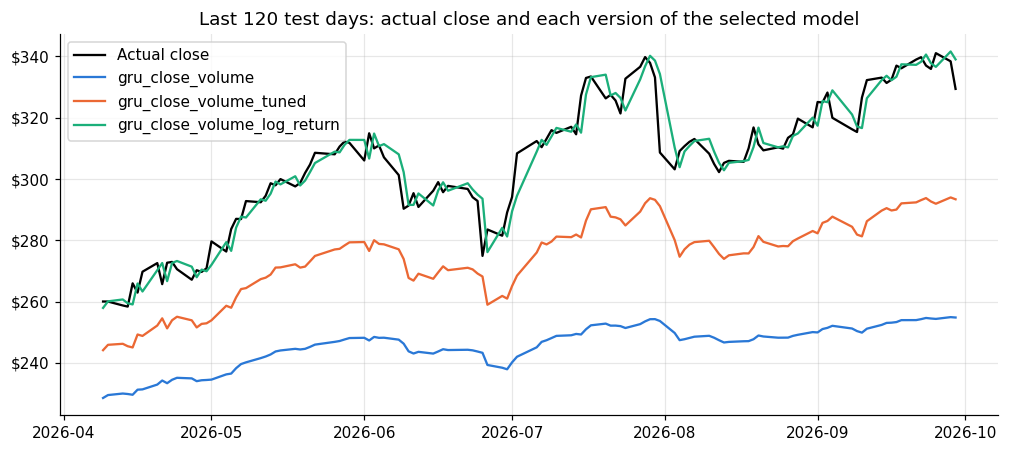

In [ ]:
# Same last-20-days replay and next-day prediction for each version of the selected model.
rows = []
for name, run in IMPROVEMENT_RUNS.items():
    next_day = predict_next_day(run.model, run.data, apple_df)
    replay = simulate_recent(run.model, run.data)
    rows.append({"run": name, "predicted close": next_day["predicted close"],
                 "predicted change (%)": next_day["predicted change (%)"],
                 "20-day MAE ($)": replay["error ($)"].abs().mean()})
display(pd.DataFrame(rows).set_index("run").round(2))

fig, ax = plt.subplots(figsize=(11, 4.5))
recent = predict_split(selected.model, selected.data).tail(120)
ax.plot(recent.index, recent["actual"], color="black", label="Actual close")
for (name, run), color in zip(IMPROVEMENT_RUNS.items(), (COLORS["blue"], COLORS["orange"], COLORS["green"])):
    ax.plot(recent.index, predict_split(run.model, run.data).tail(120)["predicted"], color=color, label=name)
ax.set_title("Last 120 test days: actual close and each version of the selected model")
dollar_axis(ax)
ax.legend(loc="upper left")
plt.show()

**Results of the improvements**

**Hyperparameter tuning.** KerasTuner tried 20 combinations in 1,303 seconds on the CPU. The best used 128 units, a dropout rate of 0.2, a learning rate of about 0.00133, and a batch size of 32. That trial reached a validation loss of 0.0040, and retraining with the same settings reached 0.0048, compared with 0.0053 for the original model. The gap between the trial and the retrained model shows how much a single training run can vary.

Tuning clearly helped: validation RMSE improved from \$3.46 to \$3.27, test RMSE fell from \$32.54 to \$16.65, and the 20-day replay MAE fell from \$78.24 to \$42.01. However, the tuned model still sits well below the actual price in the recent period, and it did not beat the baselines or the original CNN Close-only model (\$14.76).

**Log-return target.** The log-return model had the lowest validation RMSE of the three versions (\$2.73), so it is the best version under the rule set in advance. Its validation loss (0.3914) is on a different scale and cannot be compared with the others. Predicting returns removed the price-level problem: test RMSE fell to \$4.17, the 20-day replay MAE fell to \$3.85, and its next-day prediction of \$330.49 (+0.33%) is close to the last close of \$329.40.

It still did not beat the baselines. On the test set, its RMSE of \$4.17 compares with \$4.15 for drift and \$4.16 for naive, its MAE of \$2.86 compares with \$2.84 and \$2.85, and its directional accuracy of 53.80% is below drift's 55.22%. The same holds on the validation set, where naive and drift both have an RMSE of \$2.71. The replay chart shows its predictions following the actual price with about a one-day lag, so it appears to add little beyond predicting little or no change from the last close.

**Conclusion.** Both improvements reduced the errors of the selected model, and the log-return target reduced them the most, but no model outperformed the simple baselines. Overall, the project provides a controlled comparison and useful negative findings. These results come from one chronological split of one stock, and the available evidence does not support real-money deployment of any of these models.

**Remaining issues and future work**

* **Evaluation discipline:** keep the chronological test set separate from model selection, and repeat experiments over additional time periods and stocks before considering practical use.
* **Future experiments:** rolling retraining, alternative scaling methods, additional architectures, and more information sources such as market context or news sentiment, using validation data for tuning.
* **Shuffling:** training windows are kept in chronological order, as the proposal specifies. Testing shuffled windows within the training set is another possible experiment.
* **Reproducibility:** results vary slightly between computers, and GPU training may not repeat exactly. The saved outputs in this notebook come from a CPU run, which matched the team's earlier CPU run on a different computer. A full run on an NVIDIA GPU selected the same model and led to the same conclusions, with small differences in the numbers: for example, the CNN Close-only test RMSE was \$14.94 rather than \$14.76. The saved outputs in this notebook are the reference for the numbers in the text.

### References
**Academic**
- Durairaj, M., & Krishna Mohan, B. H. (2022). A convolutional neural network-based approach to financial time series prediction. *Neural Computing and Applications, 34*, 13319-13337. https://link.springer.com/article/10.1007/s00521-022-07143-2
- Lawi, A., Mesra, H., & Amir, S. (2022). Implementation of long short-term memory and gated recurrent units on grouped time-series data to predict stock prices accurately. *Journal of Big Data, 9*, 89. https://link.springer.com/article/10.1186/s40537-022-00597-0
- Li, Z., Yu, H., Xu, J., Liu, J., & Mo, Y. (2023). Stock market analysis and prediction using LSTM: A case study on technology stocks. *Innovations in Applied Engineering and Technology, 2*(1), 1-6. https://doi.org/10.62836/iaet.v2i1.162
- Qi, R., & Hu, L. (2025). Stock price prediction of Apple Inc. based on LSTM model: An application of artificial intelligence in individual stock analysis. *European Journal of AI, Computing & Informatics, 1*(3), 1-9. https://doi.org/10.71222/5hq2rh34
- Xu, Z. (2024). Factors influencing the predictive performance of the LSTM model on stock prices and its application in forecasting U.S. technology sector stock prices: Sample time span, time window length, feature selection, and prediction days. *Proceedings of the International Conference on Image Processing, Machine Learning and Pattern Recognition (IPMLP '24)*, 370-375. https://doi.org/10.1145/3700906.3700964

**Online**
- Keras documentation: KerasTuner. https://keras.io/keras_tuner/
- Keras documentation: Saving and serialization. https://keras.io/guides/serialization_and_saving/
- TensorFlow documentation: `tf.data` input pipelines. https://www.tensorflow.org/guide/data
- TensorFlow documentation: TensorBoard. https://www.tensorflow.org/tensorboard
- Team 7. (2026). Stock price deep learning project [Source code]. GitHub. https://github.com/wences-psu/Stock_Price_DL.git
- Yash (Kaggle username yash16jr). (n.d.). S&P500 All assets - Daily Updated dataset [Data set]. Kaggle. https://www.kaggle.com/datasets/yash16jr/s-and-p500-daily-update-dataset/data (accessed November 4, 2026).

### Credits

**Team 7 members:** Wenceslao Granados Gomez and Basma Hameid.

Based on the agreed division of responsibilities, Wenceslao Granados Gomez was responsible for the Close-only LSTM, GRU, and CNN configurations, and Basma Hameid was responsible for the Close+Volume LSTM, GRU, and CNN configurations. Both team members shared responsibility for data preparation, baseline comparisons, model evaluation, the final report, and the presentation.

**Code and data sources:** This code is based on the team's own project code, maintained in the Team 7 GitHub repository, and uses the public TensorFlow, Keras, and KerasTuner libraries and their documentation. The historical Apple stock data was obtained from the Kaggle dataset identified in the Data Collection section. The research papers supporting the project are listed in the References section.

**AI assistance:** Claude Code (Anthropic) assisted with refactoring the project's code into this single notebook and with editing the report text. The team reviewed the code and results.

In [ ]:
# End of Project